In [2]:
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
# Step 2: Load Dataset

df = pd.read_csv("bank.csv")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [4]:
# Step 3: Dataset Shape

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 11162
Number of Columns: 17


In [5]:
# Step 4: Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [6]:
# Step 5: Statistical Summary

df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,11162.0,NaN,NaN,NaN,41.231948,11.913369,18.0,32.0,39.0,49.0,95.0
job,11162,12,management,2566,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,11162,3,married,6351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,11162,4,secondary,5476,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,11162,2,no,10994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,11162.0,NaN,NaN,NaN,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.0,81204.0
housing,11162,2,no,5881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,11162,2,no,9702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,11162,3,cellular,8042,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,11162.0,NaN,NaN,NaN,15.658036,8.42074,1.0,8.0,15.0,22.0,31.0


In [7]:
# Step 6: Check Column Names

print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']


In [8]:
# Step 7: Check Missing Values

missing_values = df.isnull().sum()

print(missing_values)

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64


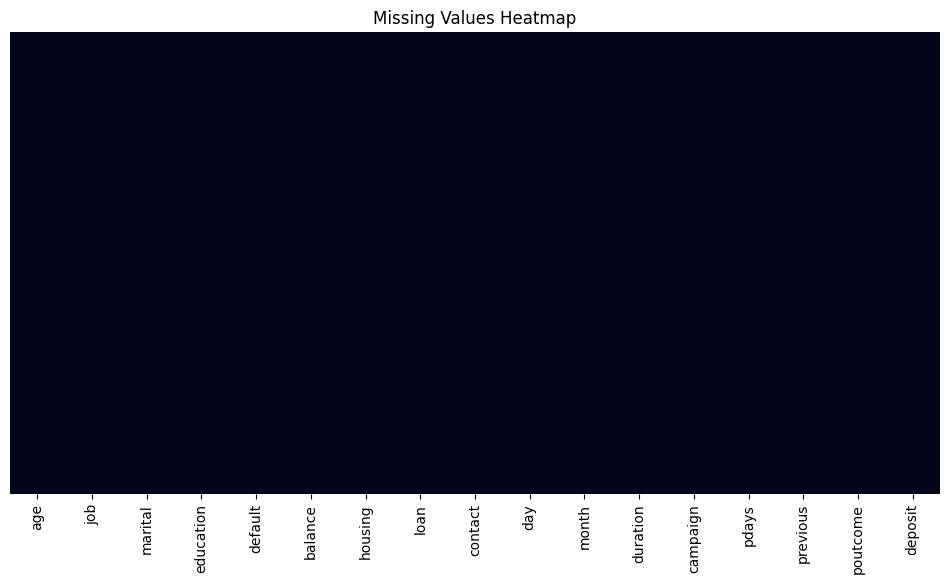

In [9]:
# Step 8: Visualize Missing Values

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Heatmap")
plt.show()

In [10]:
# Step 9: Check Duplicates

print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


In [11]:
# Step 10: Remove Duplicates

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (11162, 17)


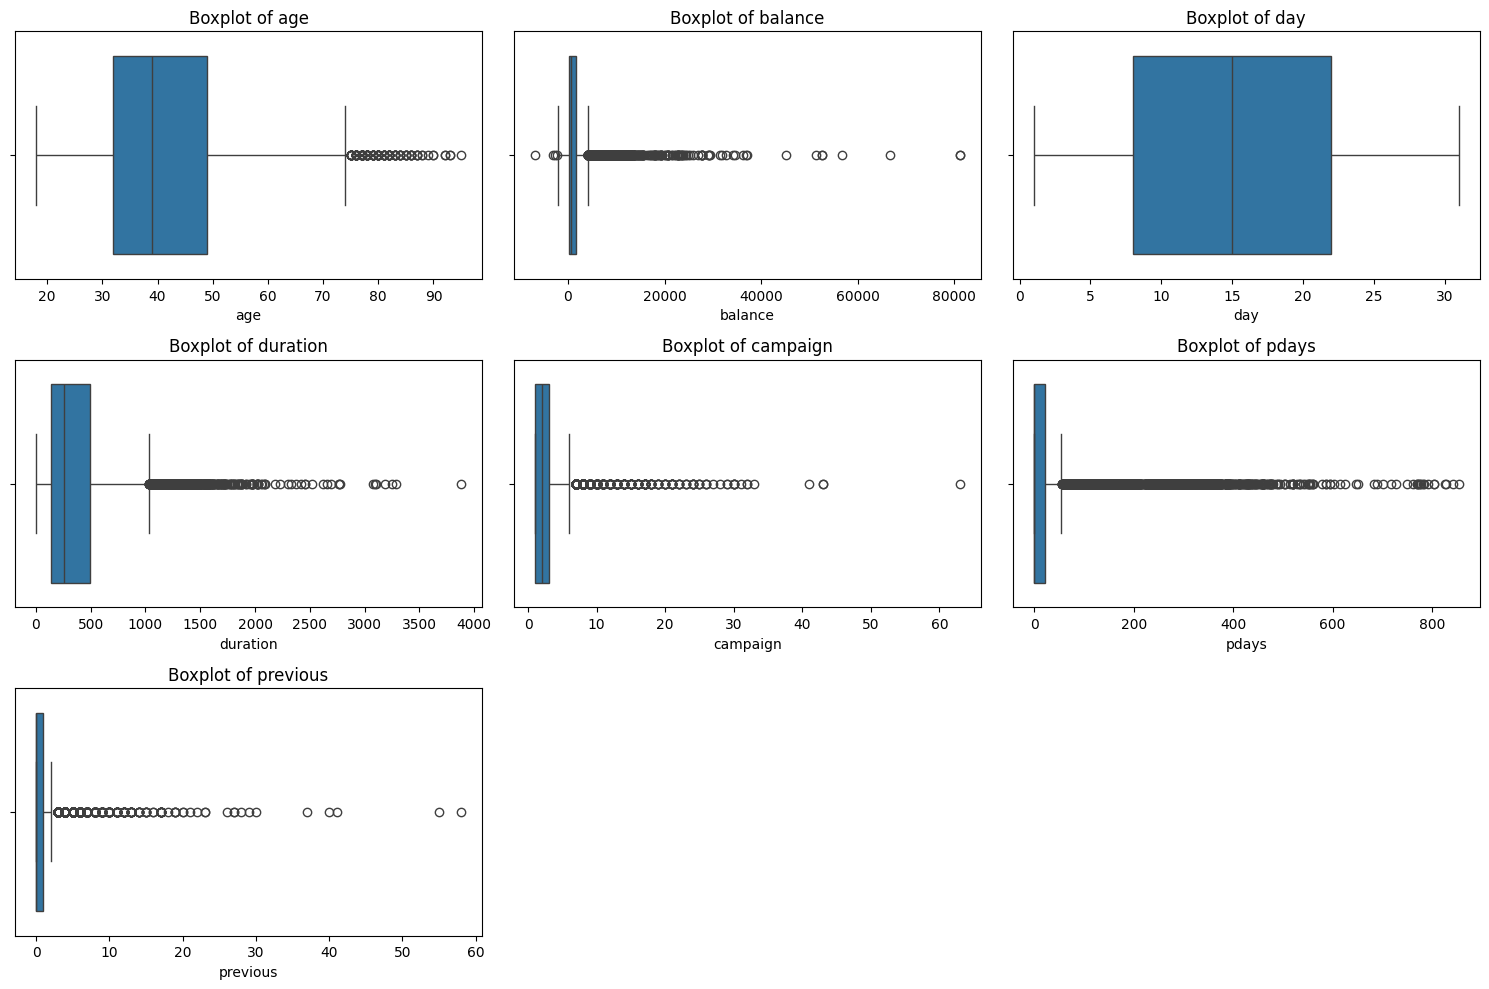

In [12]:
# Step 11: Detect Outliers Using Boxplots

numerical_columns = df.select_dtypes(
    include=np.number
).columns

plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(
        x=df[column]
    )

    plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

In [13]:
# Step 12: Detect Outliers Using IQR

outlier_summary = {}

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary[column] = len(outliers)

outlier_summary

{'age': 171,
 'balance': 1055,
 'day': 0,
 'duration': 636,
 'campaign': 601,
 'pdays': 2750,
 'previous': 1258}

In [14]:
# Step 13: Outliers Treatment Using IQR Capping

df_clean = df.copy()

for column in numerical_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_clean[column] = np.clip(
        df_clean[column],
        lower_bound,
        upper_bound
    )

print("Outliers Treatment Completed Successfully")

Outliers Treatment Completed Successfully


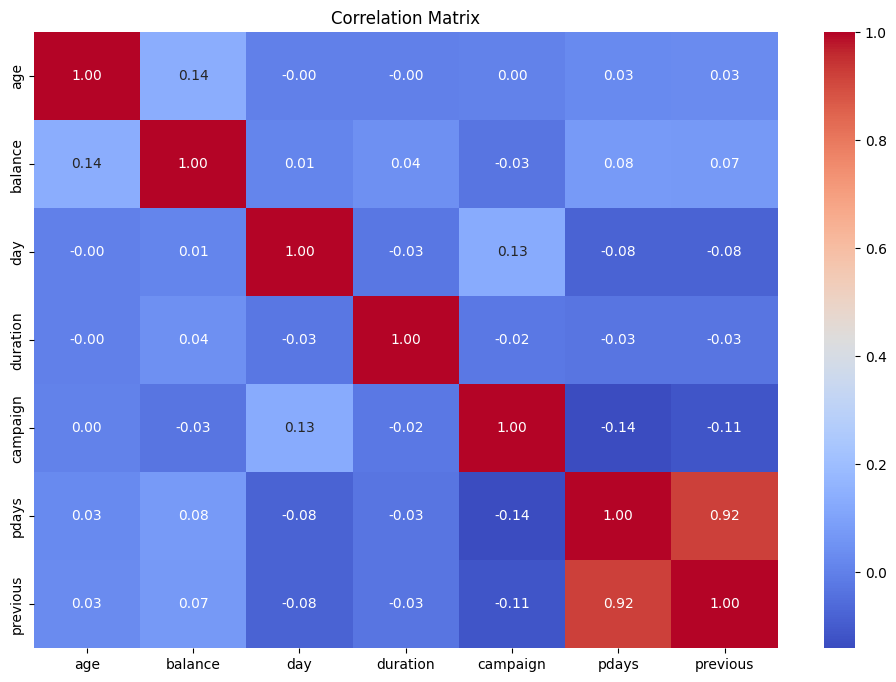

In [15]:
# Step 14: Correlation Matrix

plt.figure(figsize=(12, 8))

correlation_matrix = df_clean.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

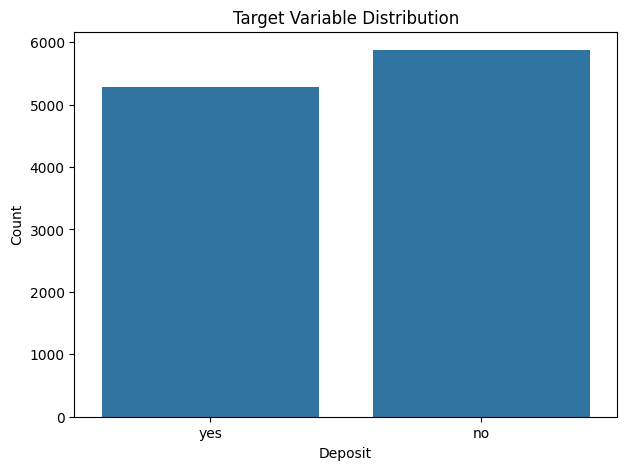

In [16]:
# Step 15: Target Analysis

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="deposit"
)

plt.title("Target Variable Distribution")
plt.xlabel("Deposit")
plt.ylabel("Count")

plt.show()

In [17]:
# Step 16: Target Percentage

target_percentage = (
    df_clean["deposit"]
    .value_counts(normalize=True)
    .mul(100)
)

print(target_percentage)

deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64


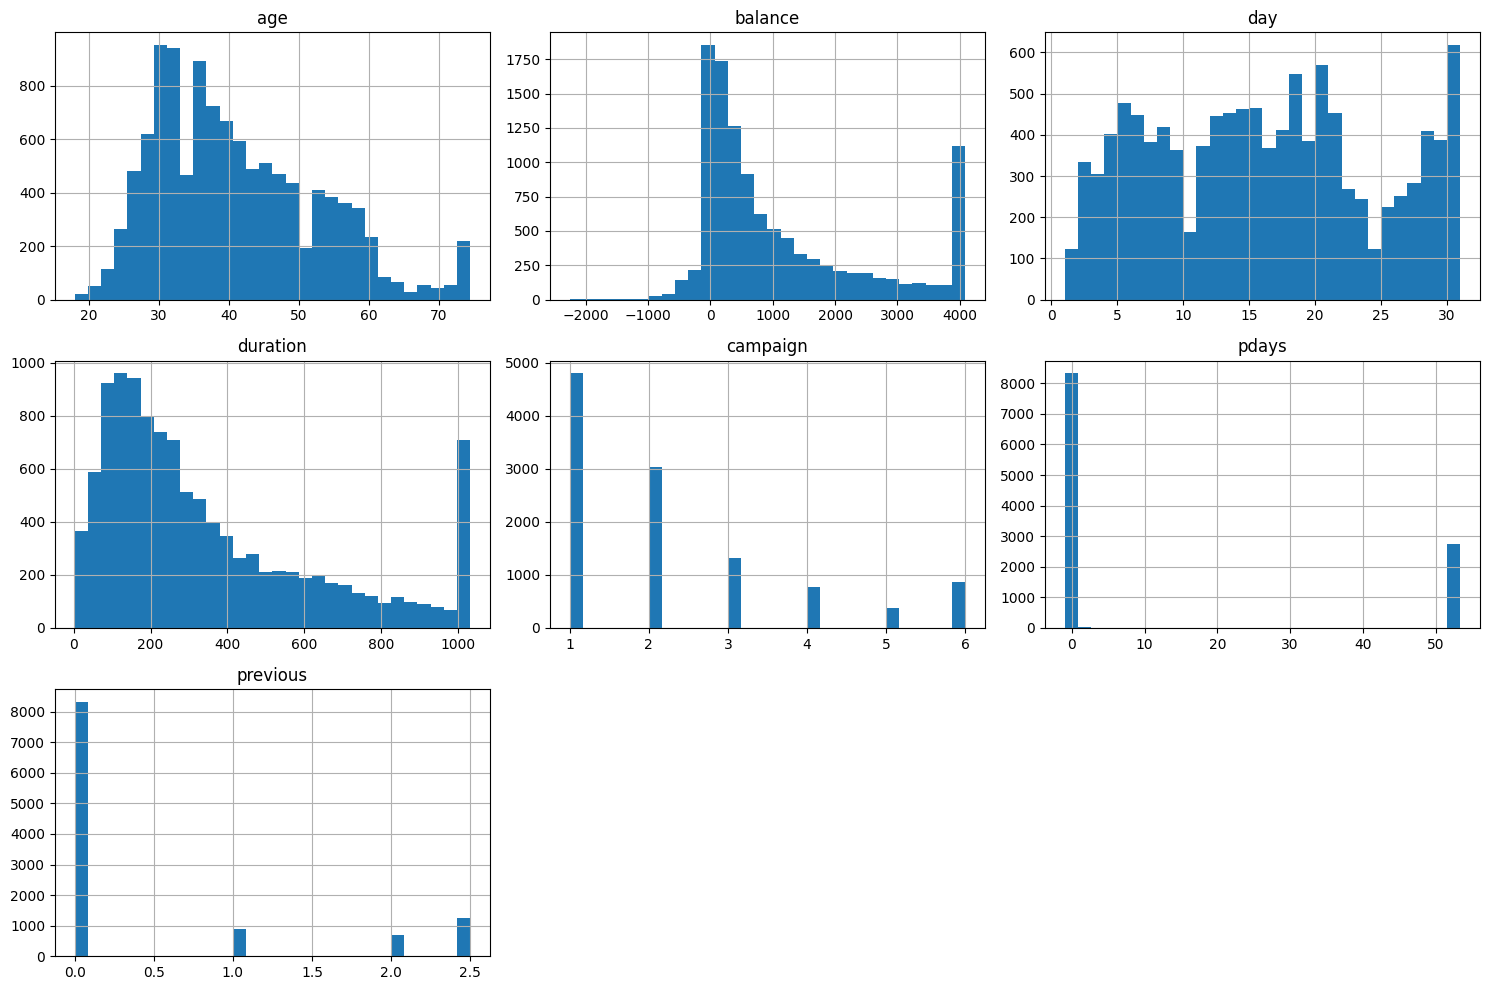

In [18]:
# Step 17: Numerical Features Distribution

df_clean[numerical_columns].hist(
    figsize=(15, 10),
    bins=30
)

plt.tight_layout()
plt.show()

In [19]:
# Step 18: Categorical Features Analysis

categorical_columns = df_clean.select_dtypes(
    exclude=np.number
).columns

print("Categorical Features:")
print(categorical_columns.tolist())

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']


In [20]:
# Step 19: Separate Features and Target

X = df_clean.drop(
    "deposit",
    axis=1
)

y = df_clean["deposit"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (11162, 16)
y Shape: (11162,)


In [21]:
# Step 20: Identify Numerical and Categorical Features

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [22]:
# Step 21: Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8929, 16)
X_test: (2233, 16)
y_train: (8929,)
y_test: (2233,)


In [23]:
# Step 22: Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

In [24]:
# Step 23: Logistic Regression

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(
    X_train,
    y_train
)

y_pred_logistic = logistic_model.predict(
    X_test
)

y_proba_logistic = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Logistic Regression Training Completed")

Logistic Regression Training Completed


In [25]:
# Step 24: Logistic Regression Classification Report

print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

              precision    recall  f1-score   support

          no       0.83      0.85      0.84      1175
         yes       0.83      0.80      0.82      1058

    accuracy                           0.83      2233
   macro avg       0.83      0.83      0.83      2233
weighted avg       0.83      0.83      0.83      2233



In [26]:
# Step 25: KNN Model

knn_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            KNeighborsClassifier(
                n_neighbors=5
            )
        )
    ]
)

knn_model.fit(
    X_train,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test
)

y_proba_knn = knn_model.predict_proba(
    X_test
)[:, 1]

print("KNN Training Completed")

KNN Training Completed


In [27]:
# Step 26: Find Best K

k_values = range(1, 21)

k_accuracies = []

for k in k_values:

    knn_temp = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                KNeighborsClassifier(
                    n_neighbors=k
                )
            )
        ]
    )

    knn_temp.fit(
        X_train,
        y_train
    )

    y_pred_temp = knn_temp.predict(
        X_test
    )

    accuracy = accuracy_score(
        y_test,
        y_pred_temp
    )

    k_accuracies.append(
        accuracy
    )

best_k = k_values[
    np.argmax(k_accuracies)
]

print("Best K:", best_k)
print(
    "Best K Accuracy:",
    max(k_accuracies)
)

Best K: 19
Best K Accuracy: 0.8289296909986565


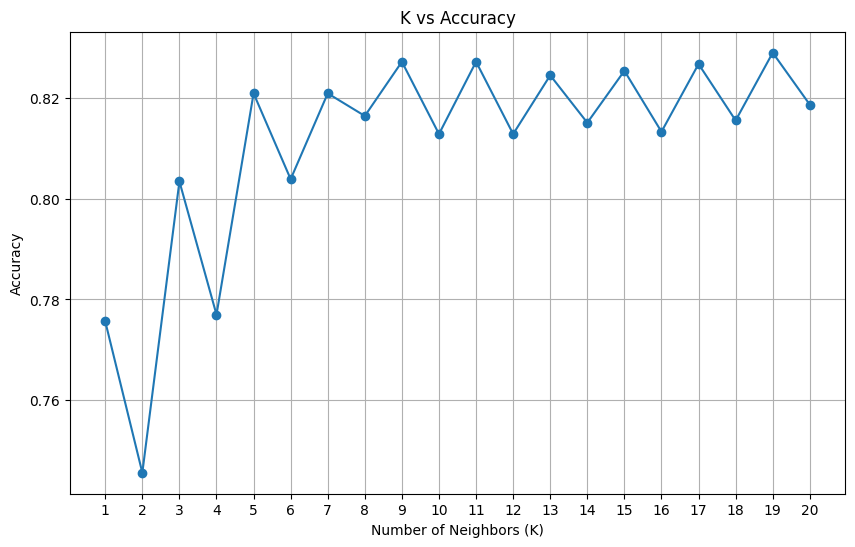

In [28]:
# Step 27: K vs Accuracy Graph

plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    k_accuracies,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")

plt.title("K vs Accuracy")

plt.xticks(
    list(k_values)
)

plt.grid()

plt.show()

In [29]:
# Step 28: Train KNN Using Best K

knn_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            KNeighborsClassifier(
                n_neighbors=best_k
            )
        )
    ]
)

knn_model.fit(
    X_train,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test
)

y_proba_knn = knn_model.predict_proba(
    X_test
)[:, 1]

print("Best KNN Model Trained Successfully")

Best KNN Model Trained Successfully


In [30]:
# Step 29: KNN Classification Report

print(
    classification_report(
        y_test,
        y_pred_knn
    )
)

              precision    recall  f1-score   support

          no       0.82      0.86      0.84      1175
         yes       0.83      0.80      0.82      1058

    accuracy                           0.83      2233
   macro avg       0.83      0.83      0.83      2233
weighted avg       0.83      0.83      0.83      2233



In [31]:
# Step 30: SVM Model

svm_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            SVC(
                probability=True,
                random_state=42
            )
        )
    ]
)

svm_model.fit(
    X_train,
    y_train
)

y_pred_svm = svm_model.predict(
    X_test
)

y_proba_svm = svm_model.predict_proba(
    X_test
)[:, 1]

print("SVM Training Completed")

SVM Training Completed


In [32]:
# Step 31: SVM Classification Report

print(
    classification_report(
        y_test,
        y_pred_svm
    )
)

              precision    recall  f1-score   support

          no       0.89      0.83      0.86      1175
         yes       0.83      0.88      0.85      1058

    accuracy                           0.86      2233
   macro avg       0.86      0.86      0.86      2233
weighted avg       0.86      0.86      0.86      2233



In [34]:
# Step 32: Random Forest Model

rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

rf_model.fit(
    X_train,
    y_train
)

y_pred_rf = rf_model.predict(
    X_test
)

y_proba_rf = rf_model.predict_proba(
    X_test
)[:, 1]

print("Random Forest Training Completed")



Random Forest Training Completed


In [35]:
# Step 33: Random Forest Classification Report
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)


              precision    recall  f1-score   support

          no       0.89      0.83      0.86      1175
         yes       0.82      0.89      0.85      1058

    accuracy                           0.86      2233
   macro avg       0.86      0.86      0.86      2233
weighted avg       0.86      0.86      0.86      2233



In [42]:
# Step 34: Feature Importance (Random Forest)

feature_names = (
    numerical_features +
    list(
        rf_model.named_steps["preprocessor"]
        .named_transformers_["cat"]
        .get_feature_names_out(categorical_features)
    )
)


importance = rf_model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(10))

             Feature  Importance
3           duration    0.330336
1            balance    0.077543
0                age    0.077492
2                day    0.069245
4           campaign    0.033801
49  poutcome_success    0.030212
34   contact_unknown    0.021205
29       housing_yes    0.017797
32  contact_cellular    0.017758
6           previous    0.017631


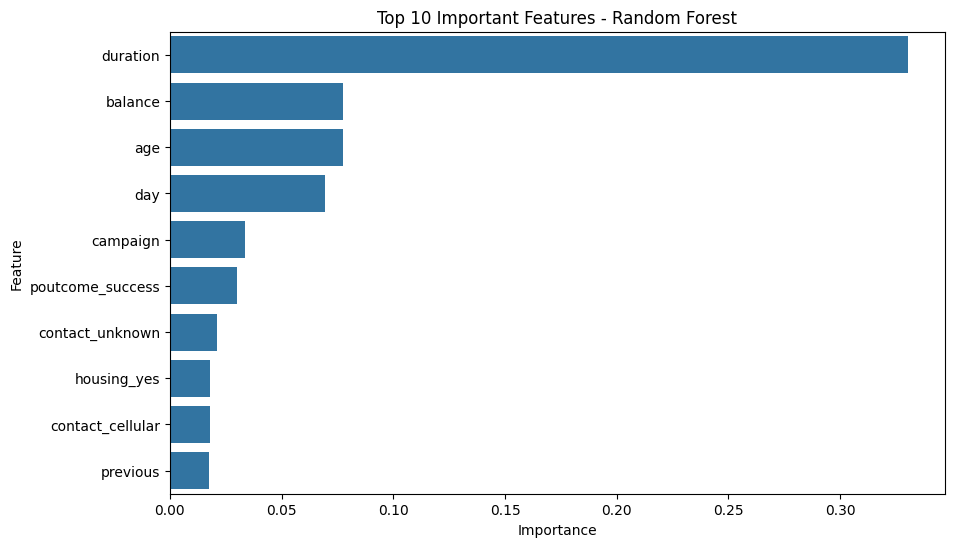

In [43]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")

plt.show()

In [36]:
# Step 35: Model Evaluation

models = {
    "Logistic Regression": (
        y_pred_logistic,
        y_proba_logistic
    ),
    "KNN": (
        y_pred_knn,
        y_proba_knn
    ),
    "SVM": (
        y_pred_svm,
        y_proba_svm
    ),
    "Random Forest": (
        y_pred_rf,
        y_proba_rf
    )
}

results = []

for model_name, (y_pred, y_proba) in models.items():

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        pos_label="yes"
    )

    recall = recall_score(
        y_test,
        y_pred,
        pos_label="yes"
    )

    f1 = f1_score(
        y_test,
        y_pred,
        pos_label="yes"
    )

    auc_score = roc_auc_score(
        y_test.map(
            {"no": 0, "yes": 1}
        ),
        y_proba
    )

    results.append(
        {
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1,
            "AUC": auc_score
        }
    )

results_df = pd.DataFrame(
    results
)

results_df

,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,Logistic Regression,0.827138,0.826214,0.804348,0.815134,0.906938
1,KNN,0.828930,0.833992,0.797732,0.815459,0.898845
2,SVM,0.856247,0.825243,0.883743,0.853492,0.919118
3,Random Forest,0.856695,0.822552,0.889414,0.854678,0.916198


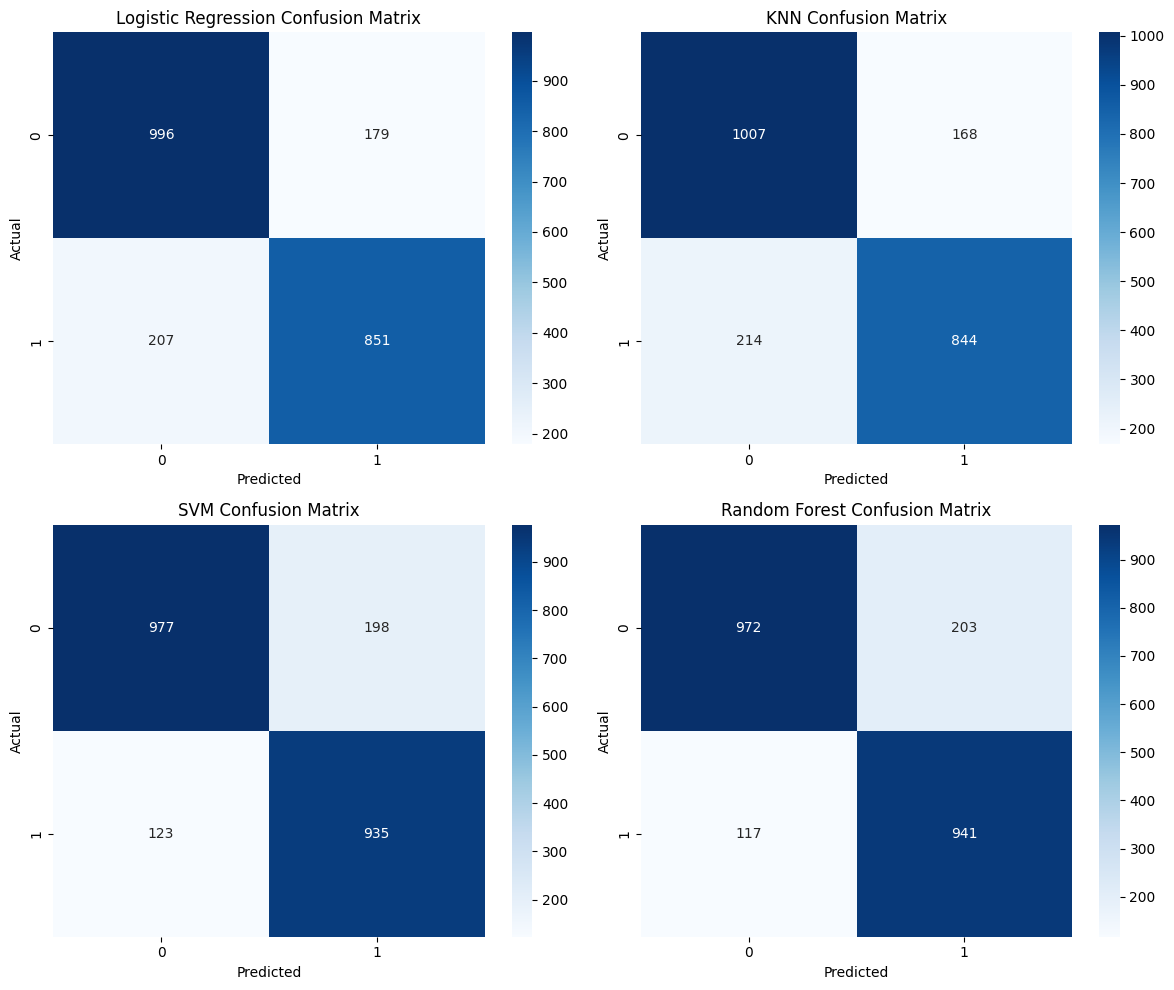

In [37]:
# Step 36: Confusion Matrix

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10)
)

axes = axes.ravel()

for ax, (model_name, (y_pred, _)) in zip(
    axes,
    models.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["no", "yes"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(
        f"{model_name} Confusion Matrix"
    )

    ax.set_xlabel(
        "Predicted"
    )

    ax.set_ylabel(
        "Actual"
    )

plt.tight_layout()
plt.show()

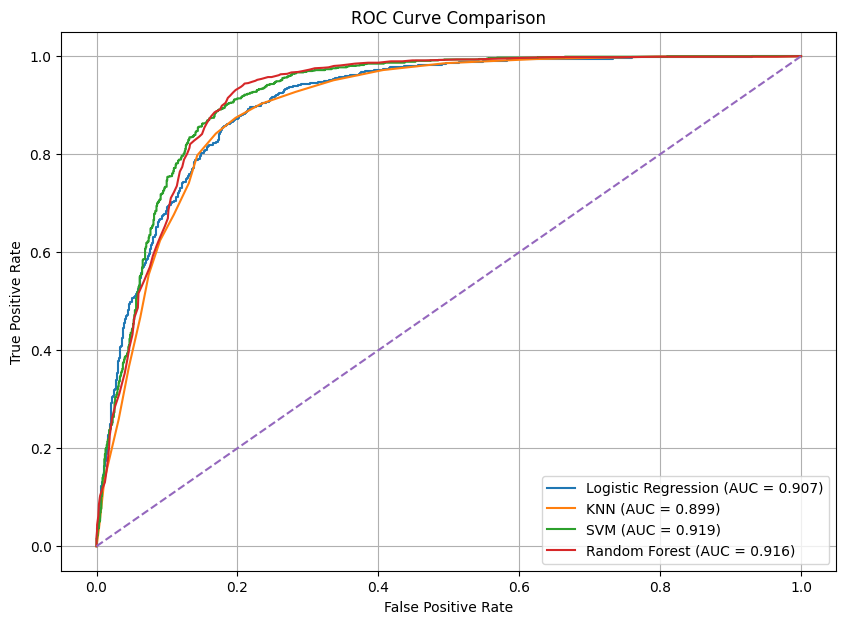

In [38]:
# Step 37: ROC Curve

y_test_binary = y_test.map(
    {
        "no": 0,
        "yes": 1
    }
)

plt.figure(figsize=(10, 7))

for model_name, (_, y_proba) in models.items():

    fpr, tpr, _ = roc_curve(
        y_test_binary,
        y_proba
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve Comparison"
)

plt.legend()

plt.grid()

plt.show()

In [39]:
# Step 38: Model Comparison

results_df_sorted = results_df.sort_values(
    by="F1-Score",
    ascending=False
)

results_df_sorted

,Model,Accuracy,Precision,Recall,F1-Score,AUC
3,Random Forest,0.856695,0.822552,0.889414,0.854678,0.916198
2,SVM,0.856247,0.825243,0.883743,0.853492,0.919118
1,KNN,0.828930,0.833992,0.797732,0.815459,0.898845
0,Logistic Regression,0.827138,0.826214,0.804348,0.815134,0.906938


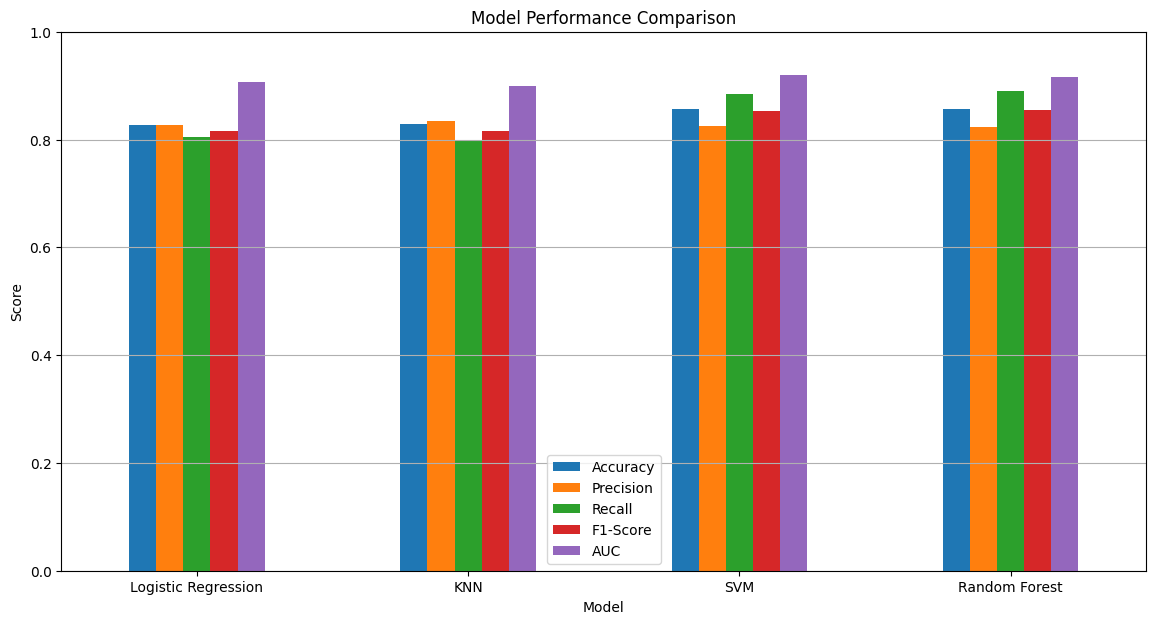

In [40]:
# Step 39: Model Comparison Visualization

results_df.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "AUC"
    ]
].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title(
    "Model Performance Comparison"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y"
)

plt.show()

In [41]:
# Step 40: Best Model

best_model_row = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print(
    "Best Model:",
    best_model_row["Model"]
)

print(
    "Accuracy:",
    round(
        best_model_row["Accuracy"],
        4
    )
)

print(
    "Precision:",
    round(
        best_model_row["Precision"],
        4
    )
)

print(
    "Recall:",
    round(
        best_model_row["Recall"],
        4
    )
)

print(
    "F1-Score:",
    round(
        best_model_row["F1-Score"],
        4
    )
)

print(
    "AUC:",
    round(
        best_model_row["AUC"],
        4
    )
)

Best Model: Random Forest
Accuracy: 0.8567
Precision: 0.8226
Recall: 0.8894
F1-Score: 0.8547
AUC: 0.9162
